# Example from the paper

we verify the toll pricing on a network with 9 nodes, 18 links and four O-D pairs (its Figure 1), and verify the results to that of the paper (Table 1 - Hearn and Ramana).

This notebook repeats that table with the functions in `src/fair_tolling`:

* `assignment.solve_assignment(project, matrix, table, objective)` solves the UE or SO with Gurobi,
* `tolling.solve_tolls(project, matrix, method)` picks tolls from the toll set,

both of which read an AequilibraE project and save into its results database. The network is in `gmns-data/nine_node`; build the project with `uv run create-ae-projects nine-node --overwrite`.

Several of the paper's toll problems have more than one optimal solution, and the paper solved to a tighter tolerance than the default used here. So the aim is to match the totals, the number of booths and the pattern, not every toll to the last digit.

In [2]:
import os
from pathlib import Path

os.environ["AEQ_SHOW_PROGRESS"] = "FALSE"  # no AequilibraE progress bars in the notebook

import matplotlib.pyplot as plt
import pandas as pd
from aequilibrae import Project

from fair_tolling import assignment as fa
from fair_tolling import tolling as ft

MATRIX = "nine-node_demand"
project = Project()
project.open(str(Path("../ae-projects/nine-node").resolve()))

## The network

Every link has the BPR time $s_a(v_a) = T_a\,(1 + 0.15\,(v_a / b_a)^4)$. Links are numbered as in Table 1, which is in order of (from node, to node).

In [3]:
links, demand = fa.load_links(project), fa.load_demand(project, MATRIX)
links[["a_node", "b_node", "fftt", "capacity"]].rename(columns={"fftt": "T", "capacity": "b"}).T

link_id,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
a_node,1.0,1.0,2.0,2.0,5.0,5.0,5.0,6.0,6.0,6.0,7.0,7.0,7.0,8.0,8.0,8.0,9.0,9.0
b_node,5.0,6.0,5.0,6.0,6.0,7.0,9.0,5.0,8.0,9.0,3.0,4.0,8.0,3.0,4.0,7.0,7.0,8.0
T,5.0,6.0,3.0,9.0,9.0,2.0,8.0,4.0,6.0,7.0,3.0,6.0,2.0,8.0,6.0,4.0,4.0,8.0
b,12.0,18.0,35.0,35.0,20.0,11.0,26.0,11.0,33.0,32.0,25.0,24.0,19.0,39.0,43.0,36.0,26.0,30.0


In [3]:
demand.to_frame().T

origin          1           2      
destination     3     4     3     4
demand       10.0  20.0  30.0  40.0

In [4]:
def plot_links(values, title, ax, fmt="{:.1f}", cmap="Reds"):
    """Draw the network with one number per link (links with value 0 are left grey and unlabelled)."""
    geo = project.network.links.data.set_index("link_id")
    nodes = project.network.nodes.data
    geo.plot(ax=ax, color="lightgrey", linewidth=1)
    shown = geo.assign(value=values)[values != 0]
    if len(shown):
        top = values.abs().max()  # subsidies and tolls share one scale, centred on zero
        shown.plot(ax=ax, column="value", cmap=cmap, linewidth=3, vmin=-top if values.min() < 0 else 0, vmax=top)
    for link_id, row in shown.iterrows():
        a, b = row.geometry.coords[0], row.geometry.coords[-1]
        # label a third of the way along, so that the two directions of a pair do not overlap
        ax.annotate(fmt.format(row.value), (a[0] + (b[0] - a[0]) / 3, a[1] + (b[1] - a[1]) / 3), fontsize=8, ha="center",
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
    nodes.plot(ax=ax, color="black", markersize=120, zorder=3)
    for _, node in nodes.iterrows():
        ax.annotate(str(node.node_id), (node.geometry.x, node.geometry.y), color="white", ha="center", va="center", fontsize=8, zorder=4)
    ax.set_title(title)
    ax.set_axis_off()

In [5]:
fa.solve_assignment(project, MATRIX, "ue", "UE")
fa.solve_assignment(project, MATRIX, "so", "SO")
ue, so = fa.link_flows(project, "ue"), fa.link_flows(project, "so")

ue_time, so_time = fa.total_time(links, ue), fa.total_time(links, so)
print(f"total travel time at the SO: {so_time:.2f} ")
print(f"total travel time at the UE: {ue_time:.2f}  ")
print(f"the UE is {100 * (ue_time / so_time - 1):.2f} ")

total travel time at the SO: 2253.92 
total travel time at the UE: 2455.87  
the UE is 8.96 


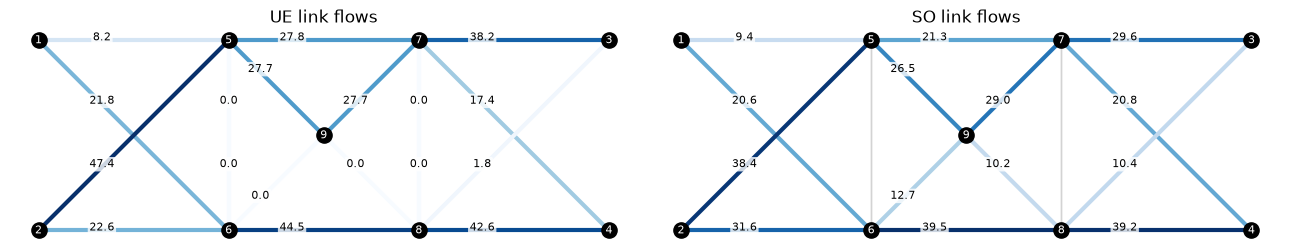

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
plot_links(ue, "UE link flows", axes[0], cmap="Blues")
plot_links(so, "SO link flows", axes[1], cmap="Blues")
plt.tight_layout()

In [7]:
METHODS = ["MSCP", "MINSYS", "MINMAX", "MINTB", "RH", "MINTB_RH"]
for method in METHODS:
    ft.solve_tolls(project, MATRIX, method)

project.results.list()[["table_name", "procedure", "timestamp"]]

,table_name,procedure,timestamp
0,ae_tolled,traffic assignment,2026-11-17 09:34:03.878732
1,tolled,traffic assignment,2026-11-17 09:34:04.084528
2,toll_minharm,toll pricing,2026-11-22 11:38:54.707044
3,ue,traffic assignment,2026-11-22 12:05:39.247001
4,so,traffic assignment,2026-11-22 12:05:39.299854
5,toll_mscp,toll pricing,2026-11-22 12:06:04.100571
6,toll_minsys,toll pricing,2026-11-22 12:06:04.195569
7,toll_minmax,toll pricing,2026-11-22 12:06:04.233295
8,toll_mintb,toll pricing,2026-11-22 12:06:04.276046
9,toll_rh,toll pricing,2026-11-22 12:06:04.317515


In [8]:
ours = pd.DataFrame({"v": so, "s(v)": fa.bpr_time(links, so), "v s(v)": so * fa.bpr_time(links, so)})
for method in METHODS:
    ours[method] = ft.load_tolls(project, f"toll_{method.lower()}")
reports = pd.DataFrame({method: fa.report_of(project, f"toll_{method.lower()}") for method in METHODS})

ours.round(3).astype(object).where(ours.round(3) != 0, "")

,v,s(v),v s(v),MSCP,MINSYS,MINMAX,MINTB,RH,MINTB_RH
link_id,,,,,,,,,
1,9.429,5.286,49.841,1.144,,,,-3.884,
2,20.571,7.535,155.006,6.141,0.016,0.007,,,
3,38.378,3.651,140.103,2.602,3.984,3.992,3.984,,
4,31.622,9.899,313.037,3.598,,,,-0.105,-3.984
5,,9.0,,,,7.974,,-2.856,
6,21.327,6.239,133.07,16.958,11.165,7.974,11.18,7.869,7.982
7,26.48,9.291,246.03,5.164,,,,-0.114,
8,,4.0,,,,7.974,,-4.0,
9,39.483,7.844,309.715,7.377,7.176,7.198,7.19,,1.114


## Verify with the paper

In [9]:
paper = pd.DataFrame(
    {
        "v": [9.411, 20.589, 38.334, 31.666, 0, 21.303, 26.442, 0, 39.474, 12.781, 29.608, 20.757, 0, 10.392, 39.243, 0, 29.062, 10.162],
        "s(v)": [5.284, 7.541, 3.648, 9.905, 9.0, 6.220, 9.284, 4.0, 7.843, 7.027, 3.885, 6.504, 2.0, 8.006, 6.624, 4.0, 4.937, 8.016],
        "MSCP": [1.135, 6.162, 2.590, 3.618, 0, 16.880, 5.135, 0, 7.370, 0.107, 3.541, 2.014, 0, 0.024, 2.497, 0, 3.746, 0.063],
        "MINSYS": [0, 0, 4.0, 0, 0, 11.2, 0, 0, 7.2, 0, 4.0, 0, 0, 0, 0, 0, 3.2, 0],
        "MINMAX": [0, 0, 8.0, 4.0, 0, 8.0, 0, 0, 7.2, 0, 7.2, 3.2, 1.079, 0, 0, 0, 0, 0],
        "RH": [0, 0, 4.0, 0, 0, 2.877, 0, 0, -0.816, 0, 2.618, 0, 0, -1.689, -0.307, 0, -5.123, -8.016],
        "MINTB_RH": [0, 0, 0, -4.0, 0, 8.0, 0, 0, 0, 0, 0, -2.126, 0, 0, 1.874, 0.121, 0, -7.2],
    },
    index=links.index,
)
paper.insert(2, "v s(v)", paper.v * paper["s(v)"])
paper["MINTB"] = paper.MINSYS  # one column in the paper: the MINSYS solution also has the fewest booths
paper = paper[ours.columns]
paper.round(3).astype(object).where(paper != 0, "")

,v,s(v),v s(v),MSCP,MINSYS,MINMAX,MINTB,RH,MINTB_RH
link_id,,,,,,,,,
1,9.411,5.284,49.728,1.135,,,,,
2,20.589,7.541,155.262,6.162,,,,,
3,38.334,3.648,139.842,2.59,4.0,8.0,4.0,4.0,
4,31.666,9.905,313.652,3.618,,4.0,,,-4.0
5,,9.0,,,,,,,
6,21.303,6.22,132.505,16.88,11.2,8.0,11.2,2.877,8.0
7,26.442,9.284,245.488,5.135,,,,,
8,,4.0,,,,,,,
9,39.474,7.843,309.595,7.37,7.2,7.2,7.2,-0.816,


In [10]:
def summary_rows(table):
    tolls = table[METHODS]
    total_time = table["v s(v)"].sum()
    revenue = tolls.mul(table.v, axis=0).sum()
    return pd.DataFrame({
        "Total tolls": revenue,
        "Total tolls / total time (%)": 100 * revenue / total_time,
        "Toll booths": (tolls.abs() > 1e-6).sum(),
        "Largest toll": tolls.max(),
    }).T

comparison = pd.concat({"ours": summary_rows(ours), "paper": summary_rows(paper)}, axis=1).swaplevel(axis=1)[METHODS]
print(f"Total time: ours {ours['v s(v)'].sum():.3f}, paper {paper['v s(v)'].sum():.3f}")
comparison.round(2)

Total time: ours 2253.922, paper 2253.995


MSCP           MINSYS          MINMAX  \
                                 ours    paper    ours   paper    ours   
Total tolls                   1494.81  1493.46  885.47  887.57  917.99   
Total tolls / total time (%)    66.32    66.26   39.29   39.38   40.73   
Toll booths                     14.00    14.00    6.00    5.00   11.00   
Largest toll                    16.96    16.88   11.17   11.20    7.97   

                                        MINTB             RH       MINTB_RH  \
                                paper    ours   paper   ours paper     ours   
Total tolls                   1167.57  886.45  887.57  -0.00 -0.02     0.00   
Total tolls / total time (%)    51.80   39.33   39.38  -0.00 -0.00     0.00   
Toll booths                      7.00    5.00    5.00  11.00  8.00     6.00   
Largest toll                     8.00   11.18   11.20   7.87  4.00     7.98   

                                    
                             paper  
Total tolls                   0.01  
Total tolls / total time (%)  0.00  
Toll booths                   6.00  
Largest toll                  8.00

In [11]:
flow_check = pd.DataFrame({"here": ours.v, "paper": paper.v, "difference": ours.v - paper.v})
print(f"largest difference in SO link flow: {flow_check.difference.abs().max():.3f} (flows are between 0 and 40)")
print(f"largest difference in MSCP toll:    {(ours.MSCP - paper.MSCP).abs().max():.3f} (largest toll is {paper.MSCP.max():.2f})")

largest difference in SO link flow: 0.071 (flows are between 0 and 40)
largest difference in MSCP toll:    0.078 (largest toll is 16.88)


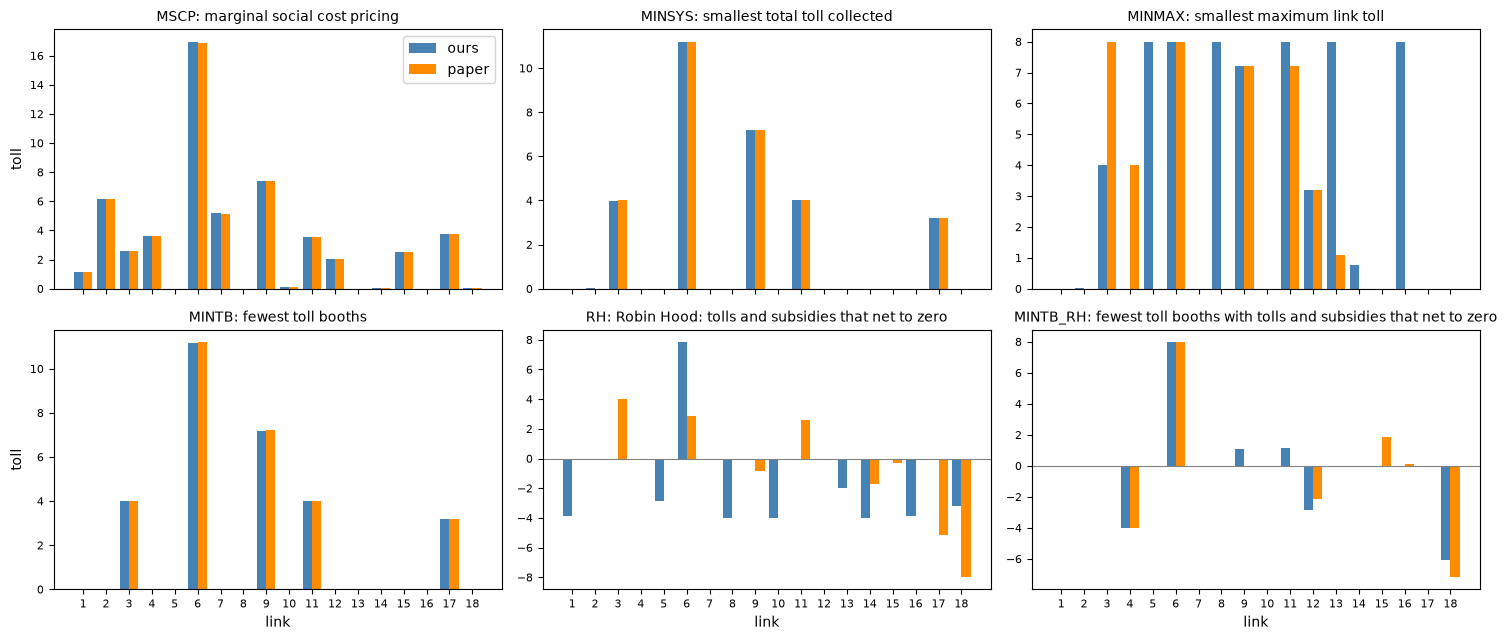

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5), sharex=True)
for ax, method in zip(axes.flat, METHODS):
    width = 0.4
    ax.bar(links.index - width / 2, ours[method], width, label="ours", color="steelblue")
    ax.bar(links.index + width / 2, paper[method], width, label="paper", color="darkorange")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_title(f"{method}: {ft.METHODS[method].split(',')[0]}", fontsize=10)
    ax.set_xticks(links.index)
    ax.tick_params(labelsize=8)
axes[0, 0].legend()
for ax in axes[1]:
    ax.set_xlabel("link")
for ax in axes[:, 0]:
    ax.set_ylabel("toll")
plt.tight_layout()

In [14]:
mscp, minsys, minmax = (reports[m] for m in ("MSCP", "MINSYS", "MINMAX"))
print(f"MSCP collects {100 * (mscp.total_tolls / minsys.total_tolls - 1):.0f} % more than MINSYS (paper: 68 %), on {mscp.toll_booths} booths against {minsys.toll_booths} or fewer")
print(f"largest toll: MSCP {mscp.max_toll:.2f}, MINSYS {minsys.max_toll:.2f}, MINMAX {minmax.max_toll:.2f}")
print(f"the untolled UE costs {100 * (ue_time / so_time - 1):.2f} % more travel time than the SO, while MINSYS tolls alone are "
      f"{minsys.tolls_over_time_pct:.0f} % of the travel time")

MSCP collects 69 % more than MINSYS (paper: 68 %), on 14 booths against 6 or fewer
largest toll: MSCP 16.96, MINSYS 11.17, MINMAX 7.97
the untolled UE costs 8.96 % more travel time than the SO, while MINSYS tolls alone are 39 % of the travel time


In [13]:
rows = {}
for method in METHODS:
    table = f"toll_{method.lower()}"
    tolls = ft.load_tolls(project, table)
    fa.solve_assignment(project, MATRIX, "tolled", "UE", toll_table=table)
    row = {"Gurobi: max |tolled UE - SO|": (fa.link_flows(project, "tolled") - so).abs().max()}
    if tolls.min() >= 0:
        graph = fa.build_graph(project, tolls=tolls)
        fa.run_assignment(project, fa.traffic_assignment(fa.traffic_class(project, graph, MATRIX), "UE"), "ae_tolled")
        row["AequilibraE: max |tolled UE - SO|"] = (fa.link_flows(project, "ae_tolled") - so).abs().max()
    rows[method] = row
check = pd.DataFrame(rows).T
check["untolled UE, for scale"] = (ue - so).abs().max()
check.round(3)

,Gurobi: max |tolled UE - SO|,AequilibraE: max |tolled UE - SO|,"untolled UE, for scale"
MSCP,0.359,0.403,12.71
MINSYS,0.220,0.196,12.71
MINMAX,0.027,0.051,12.71
MINTB,0.075,0.038,12.71
RH,0.079,NaN,12.71
MINTB_RH,0.075,NaN,12.71


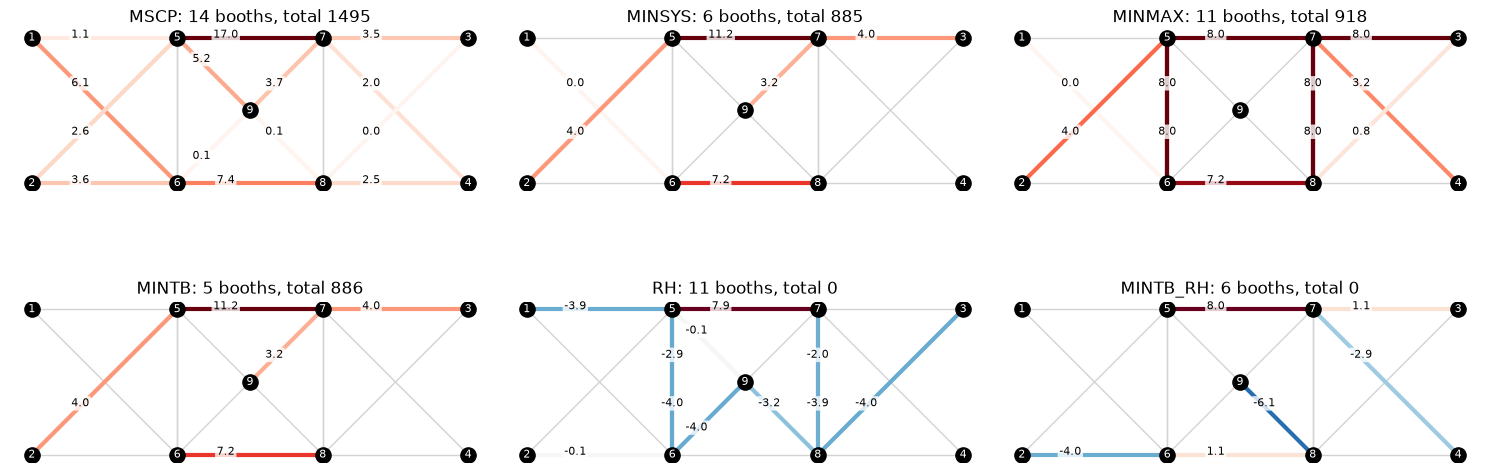

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
for ax, method in zip(axes.flat, METHODS):
    plot_links(ours[method], f"{method}: {reports[method].toll_booths} booths, total {abs(reports[method].total_tolls):.0f}", ax, cmap="RdBu_r" if ours[method].min() < 0 else "Reds")
plt.tight_layout()

In [16]:
project.close()